# Dimension Reduction on Intraday Trading-Activity Variables {-}

**Data:** WRDS *Millisecond Intraday Indicators* (`taqmsec.wrds_iid_2025`), the data set from Homework #3 and the final project.
**Methods:** PCA, Kernel PCA, ISOMAP and t-SNE, following Part 17 (PCA) and Part 18 (Nonlinear Dimension Reduction) of the lecture notes.

In [1]:
import warnings
warnings.filterwarnings(action='ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from sklearn.preprocessing import scale
from sklearn.decomposition import PCA, KernelPCA
from sklearn import manifold
from sklearn.neighbors import NearestNeighbors, kneighbors_graph
from scipy.sparse.csgraph import connected_components

pd.options.display.max_columns = 30
pd.options.display.width = 120
plt.rcParams['figure.dpi'] = 110
RANDOM_SEED = 0

## 1. The Data {-}

Each row of the WRDS table is one stock on one trading day, with about 200 daily summaries of that day's trades and quotes.
We take a fixed list of 53 S&P 500 stocks for all of 2025. The list covers all 11 GICS sectors and a wide range of share prices, from about \$11 (F) to over \$1,000 (NFLX, COST).
(GOOGL is in the list but returns no rows: TAQ stores it under the root `GOOG` with suffix `L`, and the query keeps only rows with no suffix.)

The query follows the WRDS API tutorial. Because the WRDS call needs a login, the result is cached to a `.csv` file the first time and read from that file afterwards.

In [2]:
SECTORS = {
    "Information Technology": ["AAPL", "MSFT", "NVDA", "ORCL", "ADBE", "CSCO", "INTC", "AMD"],
    "Communication Services": ["GOOGL", "META", "NFLX", "DIS", "VZ", "T"],
    "Consumer Discretionary": ["AMZN", "TSLA", "HD", "MCD", "NKE", "SBUX", "F", "CCL"],
    "Consumer Staples":       ["PG", "KO", "PEP", "WMT", "COST"],
    "Health Care":            ["JNJ", "UNH", "PFE", "MRK", "ABBV"],
    "Financials":             ["JPM", "BAC", "GS", "MS", "V", "HBAN"],
    "Energy":                 ["XOM", "CVX", "COP", "KMI"],
    "Industrials":            ["CAT", "BA", "HON", "UPS", "GE"],
    "Utilities":              ["NEE", "DUK"],
    "Materials":              ["LIN", "NEM", "FCX"],
    "Real Estate":            ["PLD", "AMT"],
}
TICKERS = [t for ts in SECTORS.values() for t in ts]
sector_of = {t: s for s, ts in SECTORS.items() for t in ts}

CACHE = "iid_2025_sample.csv"

if os.path.exists(CACHE):
    df = pd.read_csv(CACHE, parse_dates=["date"])
else:
    import wrds
    db = wrds.Connection(wrds_username="ryez")
    tick_sql = ", ".join(f"'{t}'" for t in TICKERS)
    sql_query = f"""
        SELECT *
        FROM taqmsec.wrds_iid_2025
        WHERE sym_root IN ({tick_sql})
            AND (sym_suffix IS NULL OR sym_suffix = '')
    """
    df = db.raw_sql(sql_query, date_cols=["date"])
    db.close()
    df["sector"] = df["sym_root"].map(sector_of)
    df.to_csv(CACHE, index=False)

print(f"{df.shape[0]} rows (stock-days), {df.shape[1]} columns, "
      f"{df['sym_root'].nunique()} stocks, {df['date'].nunique()} trading days")

Loading library list...
Done
13250 rows (stock-days), 209 columns, 53 stocks, 250 trading days


## 2. Choosing the Variables {-}

We use 15 variables that all measure **how much trading a stock had on a day**, broken down by type of trade.

In [ ]:
VARS = {
    "total_n_trades_m":     "Number of trades (market hours)",
    "total_dollar_m":       "Dollar volume (market hours)",
    "n_oddlot_trade":       "Number of odd-lot trades (< 100 shares)",
    "oddlot_dollar":        "Dollar volume of odd-lot trades",
    "n_iso_trade":          "Number of intermarket sweep order (ISO) trades",
    "iso_dollar":           "Dollar volume of ISO trades",
    "total_trade_retail":   "Number of retail trades",
    "total_dv_retail":      "Dollar volume of retail trades",
    "total_trade_inst20k":  "Number of institutional trades (>= $20K)",
    "total_dv_inst20k":     "Dollar volume of institutional trades (>= $20K)",
    "total_trade_inst50k":  "Number of institutional trades (>= $50K)",
    "total_dv_inst50k":     "Dollar volume of institutional trades (>= $50K)",
    "n_outside_nbbo_trade": "Number of trades priced outside the NBBO",
    "total_dollar_b":       "Dollar volume before the open (pre-market)",
    "total_dollar_a":       "Dollar volume after the close (after-hours)",
}
V = list(VARS)
pd.DataFrame({"description": VARS.values(),
              "missing": df[V].isna().sum().values,
              "zeros": (df[V] == 0).sum().values}, index=V)

ValueError: Length of values (15) does not match length of index (16)

**Why we expect these variables to be compressible.**

1. *They are nested pieces of one total.* Odd-lot, ISO, retail and institutional trades are all subsets of the day's trades. The two institutional groups are also nested in each other (every \$50K trade is a \$20K trade). When the total rises, every piece tends to rise with it.
2. *Counts and dollars are tied together by an identity.* For any group of trades,
$$
\text{dollar volume} = \text{number of trades} \times \text{average shares per trade} \times \text{price}.
$$
   Taking logs turns this product into a sum:
$$
\log(\text{dollar volume}) = \log(\text{trades}) + \log(\text{shares per trade}) + \log(\text{price}).
$$
   So after a log transform, most of the 15 variables should be close to linear combinations of a few quantities: overall activity, typical trade size and price level. That is the structure PCA can find.
3. *Some of the relationships should be nonlinear.* What counts as an "odd lot" or a "\$50K trade" is a fixed threshold, in shares or in dollars, while share prices range from \$11 to \$1,100. For a \$1,000 stock almost every retail order is an odd lot, but for a \$11 stock few are. So the mix of trade types bends with the price level. Different stocks should lie on different curves rather than along one line, which is where the nonlinear methods may add something.

**What we left out on purpose.** Prices, timestamps and identifiers are not measures of activity. We also leave out spreads, price impact and the other variables in the final project's 40-variable list, so that this homework does not anticipate the project's variable clustering. Intraday volatility (`ivol_t`) is the project's response variable, so it should not be mixed into a feature compression. It is also almost uncorrelated with these variables in logs (correlation about $-0.1$).

## 3. Preparing the Variables {-}

All 15 variables are strictly positive counts or dollar amounts with long right tails (skewness about 4–12). Products like the identity above become sums after a log, so we use $\log_{10}$ of each variable. The table below shows the skewness before and after.

In [4]:
logX = np.log10(df[V])
pd.DataFrame({"skew (raw)": df[V].skew().round(1),
              "skew (log10)": logX.skew().round(2)})

,skew (raw),skew (log10)
total_n_trades_m,5.5,1.24
total_dollar_m,4.5,1.16
n_oddlot_trade,5.8,1.32
oddlot_dollar,4.6,0.14
n_iso_trade,6.0,1.12
iso_dollar,4.8,0.95
total_trade_retail,7.2,1.31
total_dv_retail,5.0,1.33
total_trade_inst20k,4.7,0.8
total_dv_inst20k,4.7,0.91


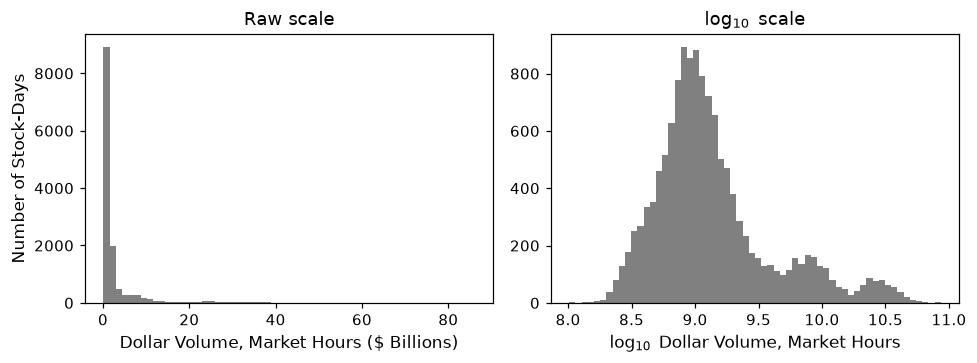

In [5]:
fig, axes = plt.subplots(1, 2, figsize=[9, 3.4])
axes[0].hist(df["total_dollar_m"] / 1e9, bins=60, color="grey")
axes[0].set_xlabel("Dollar Volume, Market Hours ($ Billions)", size=11)
axes[0].set_ylabel("Number of Stock-Days", size=11)
axes[0].set_title("Raw scale")
axes[1].hist(logX["total_dollar_m"], bins=60, color="grey")
axes[1].set_xlabel(r"$\log_{10}$ Dollar Volume, Market Hours", size=11)
axes[1].set_title(r"$\log_{10}$ scale")
plt.tight_layout()
plt.show()

The heat map shows the correlation matrix of the logged variables. Almost every pair has correlation above 0.6, and many are above 0.9. This is the first sign that a much smaller number of dimensions could carry most of the information.

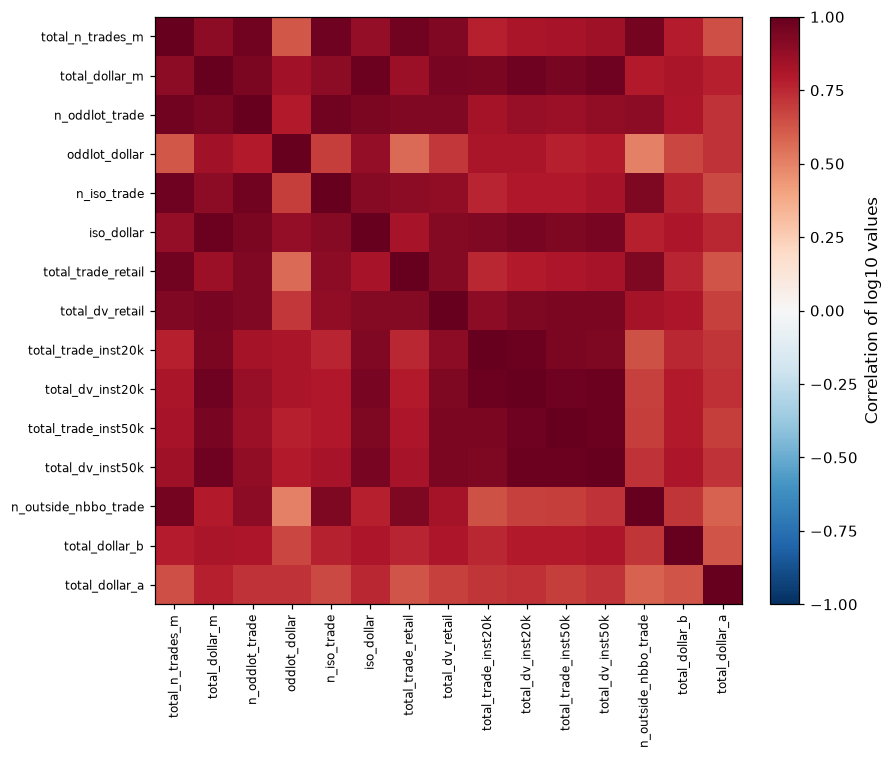

In [6]:
C = logX.corr()
fig, ax = plt.subplots(figsize=[8.2, 7])
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(V)))
ax.set_xticklabels(V, rotation=90, size=8)
ax.set_yticks(range(len(V)))
ax.set_yticklabels(V, size=8)
cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.set_label("Correlation of log10 values", size=11)
plt.tight_layout()
plt.show()

The two scatter plots below show what kind of structure is present. Each point is a stock-day, colored by that stock's median share price.

* **Left:** total trades against total dollar volume. Each stock forms its own tight streak. The streaks are shifted from one another by price level, which is the identity above at work.
* **Right:** the number of odd-lot trades against odd-lot dollar volume. The vertical offset between stocks is large, and it changes systematically with price.

So a single straight line does not describe all of the data. Once the stock is known, though, one or two numbers describe its day well.

In [7]:
df.head()

,date,sym_root,sym_suffix,buynumtrades_lr,sellnumtrades_lr,total_trade,buyvol_lr,sellvol_lr,total_vol,avg_buy_price_lr,avg_sell_price_lr,buy_dv_lr,sell_dv_lr,total_dv_lr,vwavg_buy_price_lr,...,bs_ratio_inst20k_vol,buynumtrades_inst50k,buyvol_inst50k,buy_dv_inst50k,sellnumtrades_inst50k,sellvol_inst50k,sell_dv_inst50k,total_trade_inst50k,total_vol_inst50k,total_dv_inst50k,avg_buy_price_inst50k,avg_sell_price_inst50k,bs_ratio_inst50k_num,bs_ratio_inst50k_vol,sector
0,2025-01-02,AAPL,<NA>,310901,344827,655728,22449332,25138688,47588020,244.434835,244.280923,5483846227.9,6140973572.3,11624819800.0,244.276588,...,0.04913,12442.0,11302003.0,2761890968.9,16129.0,11171865.0,2729686078.8,28571.0,22473868,5491577047.6,244.389447,244.359531,0.129047,0.005791,Information Technology
1,2025-01-02,ABBV,<NA>,29028,24735,53763,1373238,1182255,2555493,178.771501,178.742481,245573676.71,211398976.59,456972653.3,178.828198,...,0.061329,381.0,377313.0,67503085.754,453.0,316811.0,56677141.396,834.0,694124,124180227.15,178.833561,178.825124,0.086331,0.087163,Health Care
2,2025-01-02,ADBE,<NA>,36872,38592,75464,946652,1159680,2106332,444.68318,444.635498,421157869.28,515991011.49,937148880.77,444.891966,...,0.111762,694.0,253980.0,113119490.49,863.0,347425.0,154535564.2,1557.0,601405,267655054.7,444.757639,444.340345,0.108542,0.155378,Information Technology
3,2025-01-02,AMD,<NA>,172184,178256,350440,14716570,14496085,29212655,121.163133,121.024324,1785414537.3,1755970982.3,3541385519.7,121.320018,...,0.019258,5043.0,6160584.0,748304133.5,5161.0,5743160.0,695987641.82,10204.0,11903744,1444291775.3,121.313142,121.121715,0.011564,0.035067,Information Technology
4,2025-01-02,AMT,<NA>,16651,17736,34387,807486,714794,1522280,181.845355,181.874274,146900961.78,130015575.74,276916537.52,181.92385,...,0.104048,241.0,205004.0,37367931.038,224.0,156760.0,28530174.702,465.0,361764,65898105.74,182.064107,181.902662,0.036559,0.133358,Real Estate


In [9]:
df[['date', 'sym_root', 'vw_price_m']]

,date,sym_root,vw_price_m
0,2025-01-02,AAPL,244.233962
1,2025-01-02,ABBV,178.949648
2,2025-01-02,ADBE,444.429109
3,2025-01-02,AMD,121.199706
4,2025-01-02,AMT,181.732239
...,...,...,...
13245,2025-12-31,UPS,99.451268
13246,2025-12-31,V,351.803807
13247,2025-12-31,VZ,40.832712
13248,2025-12-31,WMT,111.540471


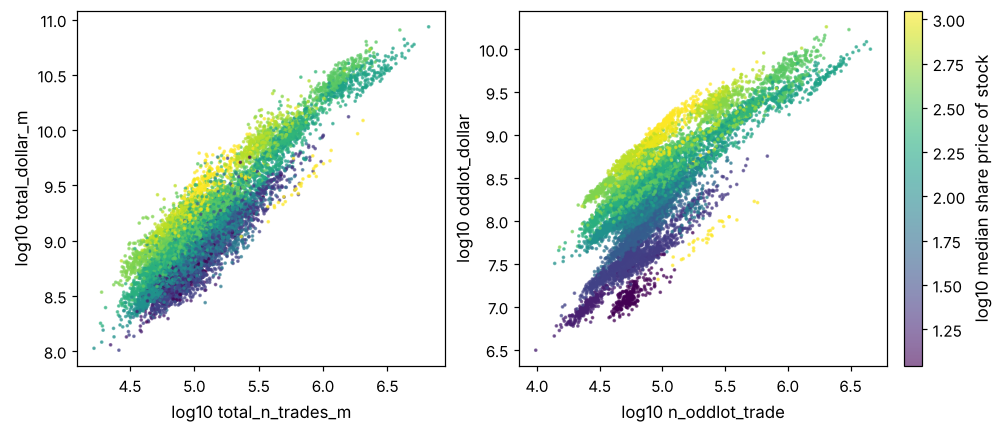

In [7]:
stock_price = df.groupby("sym_root")["vw_price_m"].median()
df["log10_price"] = np.log10(df["sym_root"].map(stock_price))

fig, axes = plt.subplots(1, 2, figsize=[10, 4.2])
pairs = [("total_n_trades_m", "total_dollar_m"), ("n_oddlot_trade", "oddlot_dollar")]
for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(logX[a], logX[b], c=df["log10_price"], cmap="viridis", s=2, alpha=0.6)
    ax.set_xlabel(f"log10 {a}", size=11)
    ax.set_ylabel(f"log10 {b}", size=11)
cbar = fig.colorbar(sc, ax=axes, fraction=0.03, pad=0.02)
cbar.set_label("log10 median share price of stock", size=11)
plt.show()

**Scaling.** Following the PCA lecture (Part 17, p. 25, *Scaling Variables for PCA*): the variables are in different units (counts and dollars) and on different scales, so each logged variable is standardized to mean 0 and variance 1 before any of the four methods is applied.

**Sample size.** PCA works on all 13,250 rows. Kernel PCA needs an $n \times n$ kernel matrix, and Isomap and t-SNE need pairwise distances. With $n = 13{,}250$ the kernel matrix alone takes about 1.4 GB. For all four methods we therefore use the same **random subsample of 60 trading days per stock**, $53 \times 60 = 3{,}180$ rows. This is large enough to show the structure and small enough that each method runs in seconds. Every stock appears equally often, so no single stock dominates the subsample.

In [8]:
Z_full = scale(logX)

sub_idx = (df.groupby("sym_root", group_keys=False)
             .sample(60, random_state=RANDOM_SEED).index)
sub = df.loc[sub_idx].reset_index(drop=True)
Z = scale(logX.loc[sub_idx])

print(f"Subsample: {Z.shape[0]} stock-days x {Z.shape[1]} variables")

Subsample: 3180 stock-days x 15 variables


**Tools used to compare the methods.**

*Coloring.* Every embedding below is a scatter plot of the low-dimensional coordinates. Each point is colored either by the stock's **sector** or by the stock's **log median price**. Neither of these was used to build the embedding, so any pattern in the colors was found by the method itself.

*Neighbor preservation.* For each point, take its $k = 10$ nearest neighbors in the original 15-dimensional standardized space and its 10 nearest neighbors in the 2-dimensional embedding. The **neighbor preservation** score is the average fraction of the first set that also appears in the second. A score of 1 means local neighborhoods are kept exactly. Random coordinates would score about $10/3180 \approx 0.003$. This gives one common yardstick for "how much local information survives" across all four methods.

In [9]:
SECTOR_COLORS = dict(zip(SECTORS, [plt.cm.tab10(i) for i in range(10)] + ["black"]))

def plot_by_sector(ax, Y, data, title, s=4):
    for sec, col in SECTOR_COLORS.items():
        m = (data["sector"] == sec).values
        ax.scatter(Y[m, 0], Y[m, 1], s=s, color=col, alpha=0.7, label=sec)
    ax.set_title(title, size=11)

def plot_by_price(ax, Y, data, title, s=4):
    sc = ax.scatter(Y[:, 0], Y[:, 1], c=data["log10_price"], cmap="viridis", s=s, alpha=0.7)
    ax.set_title(title, size=11)
    return sc

def sector_legend(fig):
    handles = [Line2D([0], [0], marker="o", ls="", color=c, label=s, markersize=6)
               for s, c in SECTOR_COLORS.items()]
    fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=8, frameon=False,
               bbox_to_anchor=(0.5, 0.0))

def neighbor_preservation(X, Y, k=10):
    """Average share of each point's k nearest neighbors in X that are also among its k nearest in Y."""
    nx = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X, return_distance=False)[:, 1:]
    ny = NearestNeighbors(n_neighbors=k + 1).fit(Y).kneighbors(Y, return_distance=False)[:, 1:]
    return np.mean([len(set(a) & set(b)) / k for a, b in zip(nx, ny)])

## 4. PCA {-}

PCA (Part 17, pp. 12–14) finds the orthogonal directions ${\bf u}_1, {\bf u}_2, \ldots$ that maximize the sample variance of the projected data. These directions are the eigenvectors of the sample covariance matrix $\widehat\Sigma$, which here is the correlation matrix because the variables were standardized. The proportion of variance explained by component $j$ is $\lambda_j / \sum_{l} \lambda_l$, where $\lambda_j$ is the $j$-th eigenvalue.

We fit PCA on the full data and on the subsample, to confirm the subsample is representative.

In [10]:
pca_full = PCA().fit(Z_full)
pca = PCA().fit(Z)
Y_pca = pca.transform(Z)[:, :2]

pd.DataFrame({"full data": pca_full.explained_variance_ratio_[:6],
              "subsample": pca.explained_variance_ratio_[:6],
              "cumulative (full)": pca_full.explained_variance_ratio_.cumsum()[:6]},
             index=[f"PC{i}" for i in range(1, 7)]).round(3)

,full data,subsample,cumulative (full)
PC1,0.843,0.842,0.843
PC2,0.068,0.069,0.911
PC3,0.031,0.031,0.942
PC4,0.020,0.020,0.962
PC5,0.019,0.019,0.981
PC6,0.006,0.006,0.987


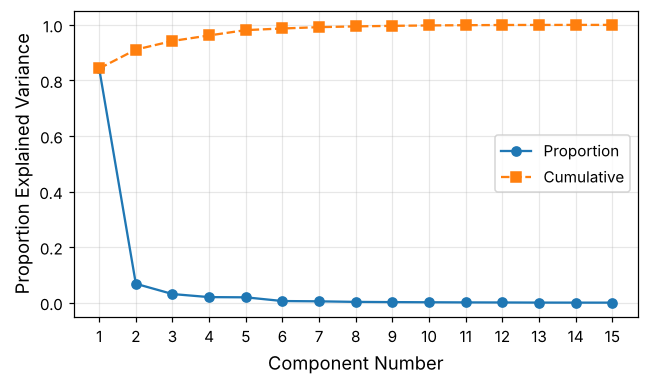

In [11]:
fig, ax = plt.subplots(figsize=[6, 3.6])
k = np.arange(1, len(V) + 1)
ax.plot(k, pca_full.explained_variance_ratio_, marker="o", label="Proportion")
ax.plot(k, pca_full.explained_variance_ratio_.cumsum(), marker="s", ls="--", label="Cumulative")
ax.set_xlabel("Component Number", size=12)
ax.set_ylabel("Proportion Explained Variance", size=12)
ax.set_xticks(k)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

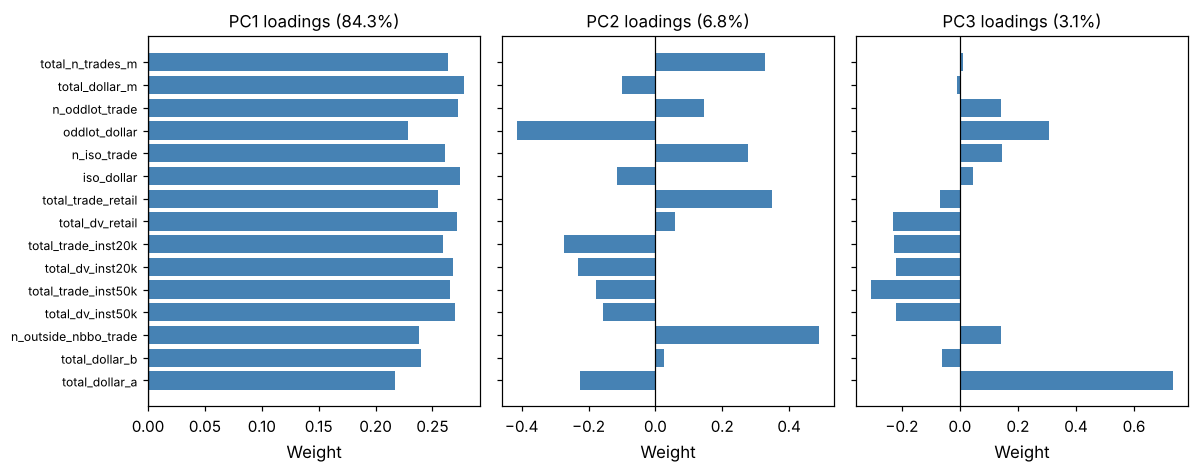

In [12]:
fig, axes = plt.subplots(1, 3, figsize=[11, 4.4], sharey=True)
for j, ax in enumerate(axes):
    ax.barh(range(len(V)), pca_full.components_[j], color="steelblue")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"PC{j+1} loadings ({pca_full.explained_variance_ratio_[j]:.1%})", size=11)
    ax.set_xlabel("Weight", size=11)
axes[0].set_yticks(range(len(V)))
axes[0].set_yticklabels(V, size=8)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

**Interpretation of the PCA.**

The first two components explain 84% and 7% of the variance, 91% together. Three components reach 94%. The scree plot has a sharp elbow after the first component and flattens after the third. Fifteen variables are therefore well summarized by two or three numbers.

* **PC1 (84%)** has almost equal positive weights on all 15 variables. It is an overall **trading-activity / size** factor: a stock-day with a high PC1 score has more trades and more dollar volume of every kind.
* **PC2 (7%)** is a contrast between **counts and dollars**. It is positive on the numbers of trades, retail trades and trades outside the NBBO, and negative on odd-lot dollars, institutional trades and after-hours dollars. From the identity in Section 2, dollars minus counts is $\log(\text{shares per trade}) + \log(\text{price})$. PC2 is therefore essentially a (negative) **average dollar size of a trade**, and that is driven mainly by the share price.
* **PC3 (3%)** is dominated by after-hours dollar volume (`total_dollar_a`), set against institutional trading. It picks up days with unusual activity after the close.

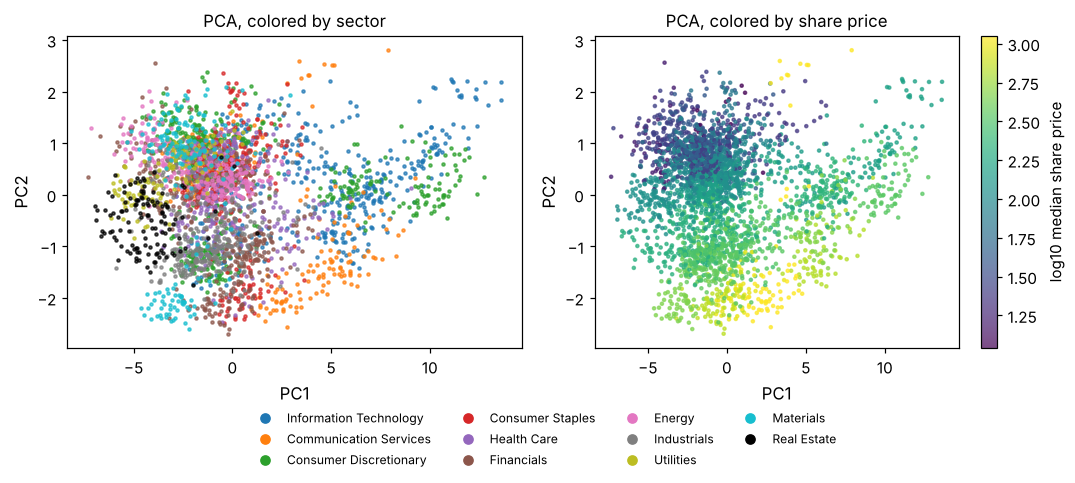

In [13]:
fig, axes = plt.subplots(1, 2, figsize=[10, 4.4])
plot_by_sector(axes[0], Y_pca, sub, "PCA, colored by sector")
sc = plot_by_price(axes[1], Y_pca, sub, "PCA, colored by share price")
for ax in axes:
    ax.set_xlabel("PC1", size=11)
    ax.set_ylabel("PC2", size=11)
cbar = fig.colorbar(sc, ax=axes[1])
cbar.set_label("log10 median share price", size=10)
sector_legend(fig)
plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

The score plots confirm this reading. PC1 runs from small, thinly traded stocks on the left (utilities, real estate) to mega-cap technology and consumer names on the right. PC2 sorts the points by share price almost perfectly: high-priced stocks (yellow) sit at the bottom and low-priced stocks (purple) at the top.

Sector, by contrast, is only loosely grouped. That is not surprising: how a stock trades depends much more on its size and price than on its industry.

The points also form small elongated clouds, one per stock. Each stock's own day-to-day variation runs mostly along the PC1 (activity) direction.

## 5. Kernel PCA {-}

Kernel PCA (Part 18, pp. 3–8) replaces the inner product ${\bf x}_i^T{\bf x}_j$ in the Gram matrix with a kernel. We use the radial basis function (RBF) kernel, as in the lecture's stock example:
$$
k({\bf x}, {\bf y}) = \exp\left(-\gamma \|{\bf x} - {\bf y}\|^2\right).
$$
The leading eigenvectors of the centered kernel matrix give the new coordinates.

The parameter $\gamma$ sets the scale of "similarity":

* With a small $\gamma$, $k \approx 1 - \gamma\|{\bf x}-{\bf y}\|^2$ for every pair, and Kernel PCA behaves almost like ordinary PCA.
* With a large $\gamma$, only very close points count as similar, and the embedding breaks into local clumps.

A natural reference point is $\gamma \approx 1/\text{median}\|{\bf x}_i - {\bf x}_j\|^2$, the value at which a typical pair has similarity $e^{-1}$. We compute that value and compare it against values ten times smaller and ten times larger.

Reference gamma = 1 / median squared distance = 0.077


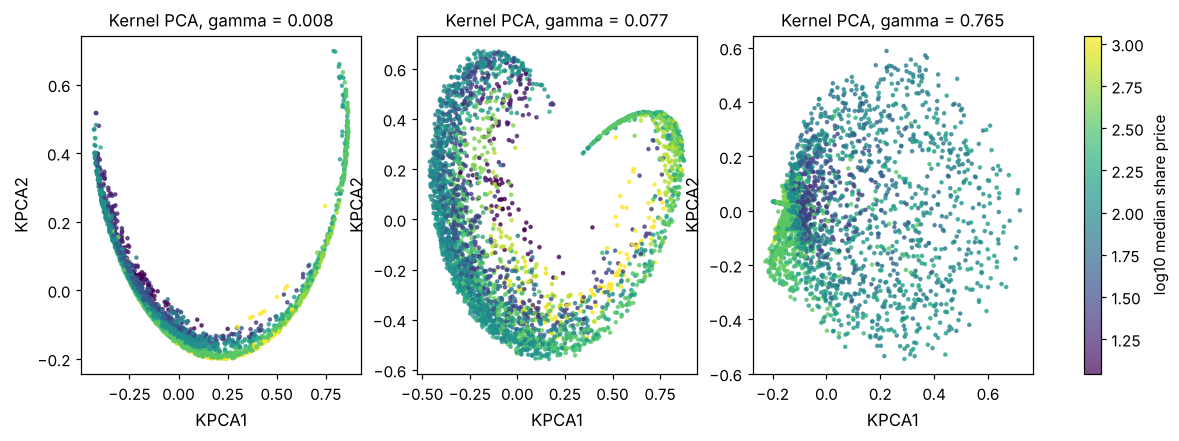

gamma = 0.008: neighbor preservation = 0.132
gamma = 0.077: neighbor preservation = 0.133
gamma = 0.765: neighbor preservation = 0.095


In [14]:
sq_d = ((Z[:, None, :] - Z[None, :, :]) ** 2).sum(-1)
gamma_ref = 1 / np.median(sq_d[np.triu_indices_from(sq_d, k=1)])
gammas = [gamma_ref / 10, gamma_ref, gamma_ref * 10]
print(f"Reference gamma = 1 / median squared distance = {gamma_ref:.3f}")

fig, axes = plt.subplots(1, 3, figsize=[12, 4])
kpca_out = {}
for ax, g in zip(axes, gammas):
    Yk = KernelPCA(n_components=2, kernel="rbf", gamma=g).fit_transform(Z)
    kpca_out[g] = Yk
    sc = plot_by_price(ax, Yk, sub, f"Kernel PCA, gamma = {g:.3f}")
    ax.set_xlabel("KPCA1", size=11)
    ax.set_ylabel("KPCA2", size=11)
cbar = fig.colorbar(sc, ax=axes, fraction=0.02)
cbar.set_label("log10 median share price", size=10)
plt.show()

for g in gammas:
    print(f"gamma = {g:.3f}: neighbor preservation = {neighbor_preservation(Z, kpca_out[g]):.3f}")

**Effect of $\gamma$.**

* With the smallest $\gamma$, the embedding is a thin **U-shaped arc**. The second coordinate is almost a deterministic function of the first. This is the well-known "horseshoe" effect: when the data are close to one-dimensional (PC1 alone explains 84%), the leading kernel eigenvectors are smooth functions of position along that one direction. The second one is roughly a quadratic in the first, so it adds no new information.
* The reference value $\gamma = 0.077$ bends the arc into a spiral. The inner edge of the spiral is ordered by share price, so the price information survives, but only along a curve.
* With the largest $\gamma$, most points collapse into a dense clump and the rest scatter. Neighbor preservation falls from 0.13 to 0.10.

We use the reference $\gamma$ below.

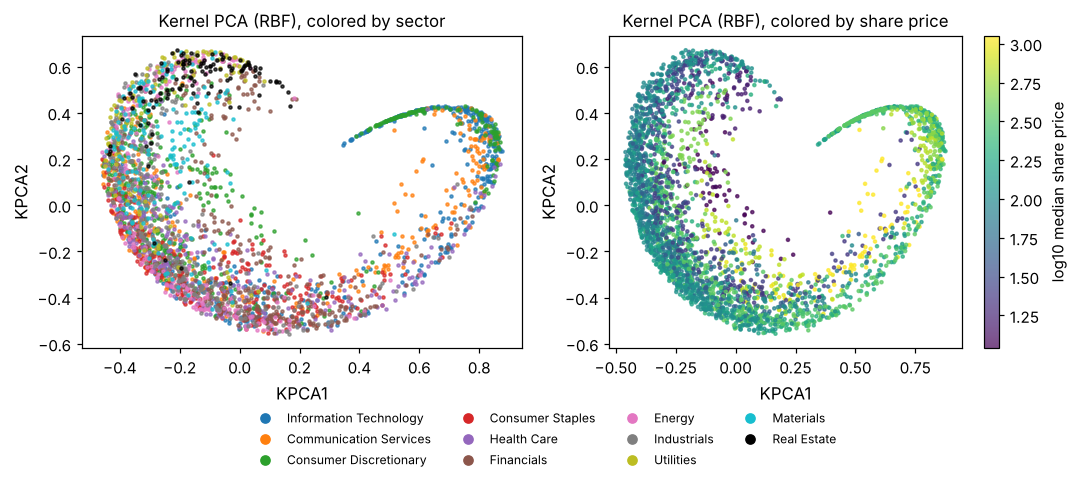

In [15]:
GAMMA = gamma_ref
kpca = KernelPCA(n_components=2, kernel="rbf", gamma=GAMMA)
Y_kpca = kpca.fit_transform(Z)

fig, axes = plt.subplots(1, 2, figsize=[10, 4.4])
plot_by_sector(axes[0], Y_kpca, sub, "Kernel PCA (RBF), colored by sector")
sc = plot_by_price(axes[1], Y_kpca, sub, "Kernel PCA (RBF), colored by share price")
for ax in axes:
    ax.set_xlabel("KPCA1", size=11)
    ax.set_ylabel("KPCA2", size=11)
cbar = fig.colorbar(sc, ax=axes[1])
cbar.set_label("log10 median share price", size=10)
sector_legend(fig)
plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

**Interpretation of Kernel PCA.** With the RBF kernel, Kernel PCA performs *worse* than linear PCA on these data. Its neighbor preservation (0.13) is lower than PCA's (0.23), and its coordinates are less correlated with stock size and price (see the comparison table in Section 8).

The reason is that the dominant structure is already close to linear in log space. The RBF kernel's way of "flattening" curved structure, which works well for the concentric circles in the lecture (Part 18, p. 15), here just wraps a straight gradient into a curve. The two coordinates then spend their capacity describing the curve rather than a second direction of variation.

## 6. ISOMAP {-}

ISOMAP (Part 18, pp. 16–21) does three things:

1. It connects each point to its $K$ nearest neighbors, with edge weights equal to the Euclidean distances.
2. It defines the distance between two points as the shortest path through this graph (the *geodesic distance*).
3. It runs MDS so that Euclidean distances in the low-dimensional space match those geodesic distances as closely as possible.

The lecture warns (p. 21) that too small a $K$ can split the graph into pieces with no path between them, and then the geodesic distances are undefined. We therefore check the number of connected components of the neighbor graph for several $K$. We also report ISOMAP's reconstruction error by output dimension, which plays the role of the scree plot.

In [16]:
for K in [5, 10, 20, 40]:
    n_comp, _ = connected_components(kneighbors_graph(Z, K), directed=False)
    print(f"K = {K:2d}: neighbor graph has {n_comp} connected component(s)")

K =  5: neighbor graph has 1 connected component(s)
K = 10: neighbor graph has 1 connected component(s)
K = 20: neighbor graph has 1 connected component(s)


K = 40: neighbor graph has 1 connected component(s)


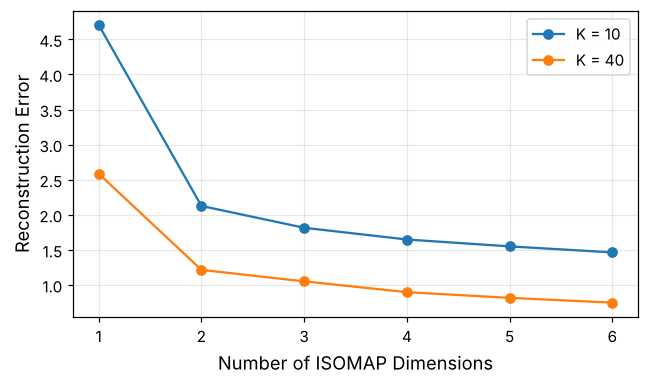

In [17]:
Ks = [10, 40]
dims = range(1, 7)
fig, ax = plt.subplots(figsize=[6, 3.6])
for K in Ks:
    err = [manifold.Isomap(n_neighbors=K, n_components=d).fit(Z).reconstruction_error() for d in dims]
    ax.plot(dims, err, marker="o", label=f"K = {K}")
ax.set_xlabel("Number of ISOMAP Dimensions", size=12)
ax.set_ylabel("Reconstruction Error", size=12)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

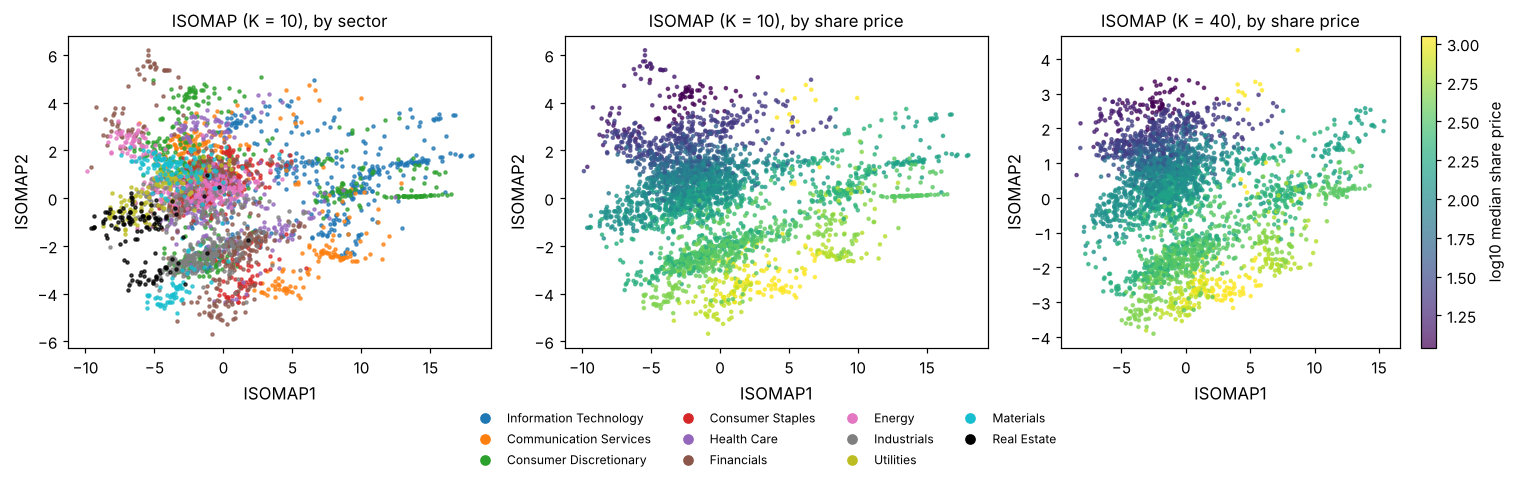

K = 10: neighbor preservation = 0.266
K = 40: neighbor preservation = 0.247


In [18]:
iso_out = {K: manifold.Isomap(n_neighbors=K, n_components=2).fit_transform(Z) for K in Ks}
Y_iso = iso_out[10]

fig, axes = plt.subplots(1, 3, figsize=[14, 4.4])
plot_by_sector(axes[0], iso_out[10], sub, "ISOMAP (K = 10), by sector")
plot_by_price(axes[1], iso_out[10], sub, "ISOMAP (K = 10), by share price")
sc = plot_by_price(axes[2], iso_out[40], sub, "ISOMAP (K = 40), by share price")
for ax in axes:
    ax.set_xlabel("ISOMAP1", size=11)
    ax.set_ylabel("ISOMAP2", size=11)
cbar = fig.colorbar(sc, ax=axes[2])
cbar.set_label("log10 median share price", size=10)
sector_legend(fig)
plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

for K in Ks:
    print(f"K = {K}: neighbor preservation = {neighbor_preservation(Z, iso_out[K]):.3f}")

**Interpretation of ISOMAP.**

* **Connectivity.** The neighbor graph is connected for every $K$ tried, so the geodesic distances are well defined.
* **Number of dimensions.** The reconstruction error has a clear elbow at 2 dimensions for both $K = 10$ and $K = 40$. This agrees with PCA: the data are essentially two-dimensional, plus noise.
* **What the 2-D map shows.** It looks similar to PCA: ISOMAP1 is activity/size and ISOMAP2 is share price. But the price ordering along ISOMAP2 is cleaner (|corr| 0.83 against 0.78 for PC2), and local neighborhoods are better preserved (0.27 against 0.23).
* **Within-stock variation.** Several stocks show up as short straight streaks, for example the horizontal lines on the right for the largest stocks. Following the graph, rather than straight-line distance, keeps each stock's days in a line along its own activity direction.
* **Sensitivity to $K$.** With $K = 40$ the picture is nearly the same but slightly smoother (preservation 0.25). Larger neighborhoods move ISOMAP back toward ordinary MDS/PCA.

## 7. t-SNE {-}

t-SNE (Part 18, pp. 24–29) converts distances into neighbor probabilities.

* In the original space, $p_{j|i}$ uses a Gaussian kernel. Its width $\sigma_i$ is chosen separately for each point so that the distribution has a set **perplexity**, which works like an effective number of neighbors.
* In the embedding, $q_{ij}$ uses a heavy-tailed Cauchy (Student-$t$ with one degree of freedom) kernel.
* The coordinates are chosen to minimize the Kullback–Leibler divergence $\sum_{i\neq j} p_{ij}\log(p_{ij}/q_{ij})$.

The heavy tails push dissimilar points far apart. Because of this, distances *between* clusters in a t-SNE plot are not meaningful. Only the grouping is.

We compare perplexities 5, 30 (the scikit-learn default) and 100.

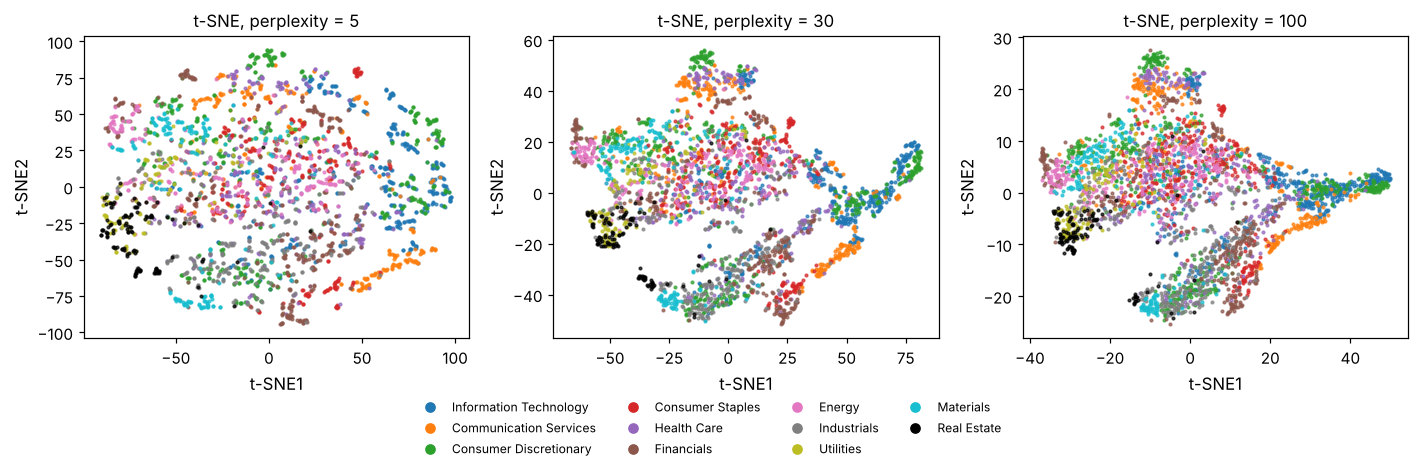

perplexity =   5: neighbor preservation = 0.512
perplexity =  30: neighbor preservation = 0.555
perplexity = 100: neighbor preservation = 0.493


In [19]:
perps = [5, 30, 100]
tsne_out = {p: manifold.TSNE(n_components=2, perplexity=p, random_state=RANDOM_SEED).fit_transform(Z)
            for p in perps}
Y_tsne = tsne_out[30]

fig, axes = plt.subplots(1, 3, figsize=[13, 4.3])
for ax, p in zip(axes, perps):
    plot_by_sector(ax, tsne_out[p], sub, f"t-SNE, perplexity = {p}", s=3)
    ax.set_xlabel("t-SNE1", size=11)
    ax.set_ylabel("t-SNE2", size=11)
sector_legend(fig)
plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

for p in perps:
    print(f"perplexity = {p:3d}: neighbor preservation = {neighbor_preservation(Z, tsne_out[p]):.3f}")

**Effect of perplexity.**

* At **perplexity 5**, t-SNE breaks the data into many small islands. Often one stock is split into several islands, because each point only looks at about 5 neighbors.
* At **perplexity 100**, the islands merge into a few large arms.
* **Perplexity 30** gives the best neighbor preservation, 0.56, about twice that of PCA or ISOMAP.

As with the other methods, the sector colors are only loosely grouped.

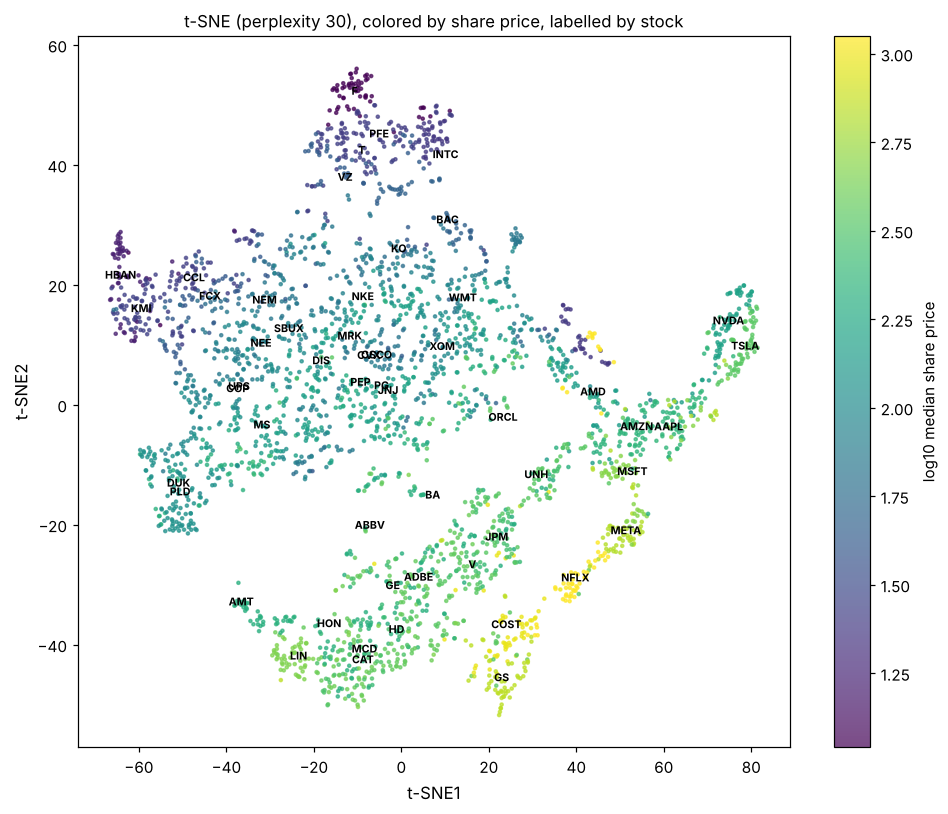

In [20]:
# Which stock is each t-SNE island? Label each island at the median position of its stock.
fig, ax = plt.subplots(figsize=[9, 7.5])
sc = plot_by_price(ax, Y_tsne, sub, "t-SNE (perplexity 30), colored by share price, labelled by stock", s=4)
centers = pd.DataFrame(Y_tsne, columns=["x", "y"]).groupby(sub["sym_root"].values).median()
for tic, r in centers.iterrows():
    ax.text(r["x"], r["y"], tic, size=7, ha="center", va="center", weight="bold")
ax.set_xlabel("t-SNE1", size=11)
ax.set_ylabel("t-SNE2", size=11)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("log10 median share price", size=10)
plt.tight_layout()
plt.show()

**Interpretation of t-SNE.** Labelling each island by its stock shows that **each island is (mostly) one stock**: t-SNE has recovered the stock identity without being told it. The overall arrangement still follows the same two drivers as PCA.

* Low-priced stocks (F, HBAN, KMI, CCL, PFE, T, INTC) are at the top and left.
* Mid-priced, mid-sized names fill the center.
* The most actively traded technology stocks (NVDA, TSLA, AAPL, AMZN, MSFT, META) form an arm on the right.
* High-priced stocks (COST, GS, NFLX, LIN, CAT) are at the bottom.

**A detail that shows t-SNE is picking up real structure:** a small group of NFLX points sits apart from the main NFLX island, near AMD. These are NFLX's trading days **after its 10-for-1 stock split in November 2025**. After the split NFLX traded at about \$100 instead of \$1,100, so its mix of odd lots, trade counts and trade sizes changed overnight. t-SNE places those days with other \$100–\$200 stocks.

Recall (Part 18, p. 27) that the heavy-tailed $q_{ij}$ pushes dissimilar points far apart. So the gaps *between* islands should not be read as distances. Only membership in an island is meaningful.

## 8. Comparing the Four Methods {-}

The table puts the four 2-D representations on the same footing.

* **neighbor pres.** (neighbor preservation) is the local measure defined in Section 3.
* **same-stock nbrs** is the share of each point's 10 nearest neighbors in the embedding that belong to the *same stock*. The last row gives the same share in the original 15-D space, as a benchmark.
* **|corr| size** is the largest absolute correlation of either embedding coordinate with the stock's mean log dollar volume. **|corr| price** is the same with the stock's log median price.

In [21]:
def same_stock_share(Y, labels, k=10):
    nn = NearestNeighbors(n_neighbors=k + 1).fit(Y).kneighbors(Y, return_distance=False)[:, 1:]
    return np.mean(labels[nn] == labels[:, None])

labels = sub["sym_root"].to_numpy(dtype=str)
stock_size = sub["sym_root"].map(logX.groupby(df["sym_root"])["total_dollar_m"].mean()).values

emb = {"PCA": Y_pca, "Kernel PCA": Y_kpca, "ISOMAP (K=10)": Y_iso, "t-SNE (perp 30)": Y_tsne}
rows = {}
for name, Y in emb.items():
    rows[name] = {
        "neighbor pres.": neighbor_preservation(Z, Y),
        "same-stock nbrs": same_stock_share(Y, labels),
        "|corr| size": max(abs(np.corrcoef(Y[:, j], stock_size)[0, 1]) for j in range(2)),
        "|corr| price": max(abs(np.corrcoef(Y[:, j], sub["log10_price"])[0, 1]) for j in range(2)),
    }
rows["original 15-D space"] = {"same-stock nbrs": same_stock_share(Z, labels)}
pd.DataFrame(rows).T.round(3)

,neighbor pres.,same-stock nbrs,|corr| size,|corr| price
PCA,0.225,0.234,0.936,0.777
Kernel PCA,0.133,0.143,0.771,0.365
ISOMAP (K=10),0.266,0.291,0.941,0.827
t-SNE (perp 30),0.555,0.390,0.894,0.802
original 15-D space,NaN,0.418,NaN,NaN


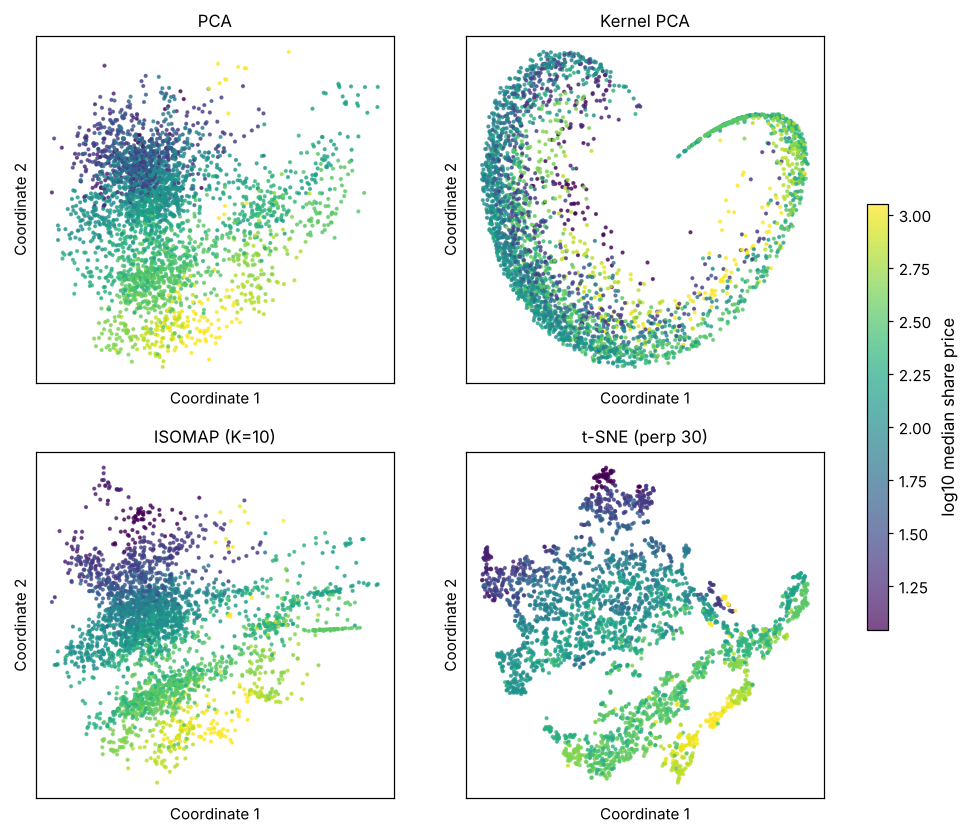

In [22]:
fig, axes = plt.subplots(2, 2, figsize=[10, 9])
for ax, (name, Y) in zip(axes.flatten(), emb.items()):
    sc = plot_by_price(ax, Y, sub, name, s=3)
    ax.set_xlabel("Coordinate 1", size=10); ax.set_ylabel("Coordinate 2", size=10)
    ax.set_xticks([]); ax.set_yticks([])
cbar = fig.colorbar(sc, ax=axes, fraction=0.025)
cbar.set_label("log10 median share price", size=11)
plt.show()

**Comparison.**

* **Global structure.** All four methods agree on what matters globally: the first coordinate is stock size (|corr| 0.77–0.94) and the second is share price, equivalently average trade size. Fifteen variables are mostly two numbers, plus each stock's own day-to-day wiggle.
* **PCA is hard to beat for global structure.** Two components keep 91% of the variance, and the coordinates have a direct interpretation through the loadings. Because the logged variables are related almost linearly, the nonlinear methods have little global curvature to "unroll".
* **ISOMAP** gives a slightly cleaner picture than PCA, with better local preservation and a cleaner price axis, at modest cost.
* **Kernel PCA with an RBF kernel** is the weakest here. It bends a nearly linear gradient into a curve (the horseshoe effect) and keeps the fewest neighbors.
* **t-SNE** preserves local neighborhoods far better than the others (0.56). It is the only method whose embedding keeps nearly as many same-stock neighbors (0.39) as the original space (0.42), and it isolates real events such as the NFLX split. Its axes, however, have no meaning, and the distances between islands do not mean anything either. It is a tool for *seeing* structure, not for building a factor to put into a regression.

## 9. Extension: Day-to-Day Variation Within Each Stock {-}

So far all four methods are dominated by differences *between* stocks. About 80–90% of the variance of each logged variable is between-stock variance. Day-to-day variation within a stock is arguably the more interesting part for trading, so we repeat the analysis after **removing each stock's own mean** from every logged variable:
$$
\tilde x_{s,t,j} = \log_{10} x_{s,t,j} - \frac{1}{250}\sum_{t'} \log_{10} x_{s,t',j}.
$$
Here $s$ is the stock, $t$ the trading day and $j$ the variable. Each $\tilde x$ is then standardized across the whole sample.

After this step, a point's position can only reflect how unusual that day was *for that stock*.

To color the results we flag three kinds of market-wide days, none of which are used in the fit:

* **quarterly options/futures expiry ("quad witching")**: Mar 21, Jun 20, Sep 19 and Dec 19;
* **the April 2025 tariff shock**: Apr 3–10;
* **half trading days**: the NYSE early closes at 1:00 pm on Jul 3, Nov 28 and Dec 24.

In [23]:
between_share = logX.groupby(df["sym_root"]).transform("mean").var() / logX.var()
print("Share of each variable's variance that is between stocks:")
print(between_share.round(2).sort_values().to_string())

Share of each variable's variance that is between stocks:
total_dollar_a          0.66
total_dollar_b          0.70
n_iso_trade             0.79
n_outside_nbbo_trade    0.82
total_n_trades_m        0.84
iso_dollar              0.85
total_trade_retail      0.86
n_oddlot_trade          0.86
total_trade_inst20k     0.86
total_dv_inst50k        0.87
total_dollar_m          0.87
total_dv_inst20k        0.88
total_trade_inst50k     0.88
total_dv_retail         0.89
oddlot_dollar           0.91


In [24]:
within = logX - logX.groupby(df["sym_root"]).transform("mean")
Zw = scale(within.loc[sub_idx])

half_days = pd.to_datetime(["2025-07-03", "2025-11-28", "2025-12-24"])   # NYSE 1:00 pm early closes
quad = pd.to_datetime(["2025-03-21", "2025-06-20", "2025-09-19", "2025-12-19"])
tariff = pd.date_range("2025-04-03", "2025-04-10")
day_type = np.select([sub["date"].isin(quad), sub["date"].isin(tariff), sub["date"].isin(half_days)],
                     ["Quad witching", "Tariff shock (Apr 3-10)", "Half trading day"], "Other day")
DAY_COLORS = {"Other day": "lightgrey", "Quad witching": "crimson",
              "Tariff shock (Apr 3-10)": "darkorange", "Half trading day": "royalblue"}
print(pd.Series(day_type).value_counts().to_string())

pca_w = PCA().fit(Zw)
print("\nWithin-stock PCA, proportion of variance:", np.round(pca_w.explained_variance_ratio_[:5], 3))

Other day                  3027
Tariff shock (Apr 3-10)      81
Quad witching                45
Half trading day             27

Within-stock PCA, proportion of variance: [0.681 0.085 0.064 0.054 0.034]


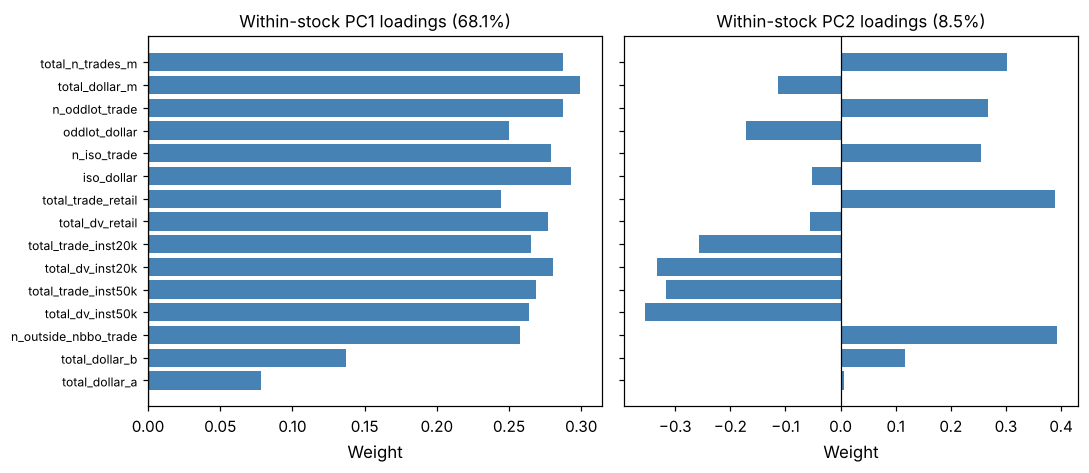

In [25]:
fig, axes = plt.subplots(1, 2, figsize=[10, 4.4], sharey=True)
for j, ax in enumerate(axes):
    ax.barh(range(len(V)), pca_w.components_[j], color="steelblue")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Within-stock PC{j+1} loadings ({pca_w.explained_variance_ratio_[j]:.1%})", size=11)
    ax.set_xlabel("Weight", size=11)
axes[0].set_yticks(range(len(V)))
axes[0].set_yticklabels(V, size=8)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

Between-stock differences account for 66–91% of the variance of every variable, which is why the stocks dominated the analysis above.

After the stock means are removed, the first within-stock component still explains 68% of the variance. PC1 is again an "activity" factor: on a given day a stock is unusually busy in every trade category at once. The pre-market and after-hours variables have much smaller weights, so extended-hours activity behaves somewhat independently.

Within-stock PC2 (8.5%) is a contrast between **small/retail trades** (trade counts, retail trades, ISO trades, trades outside the NBBO) and **large institutional trades** (\$20K and \$50K trades). A day with a high PC2 score had many more small trades than usual relative to its institutional block flow.

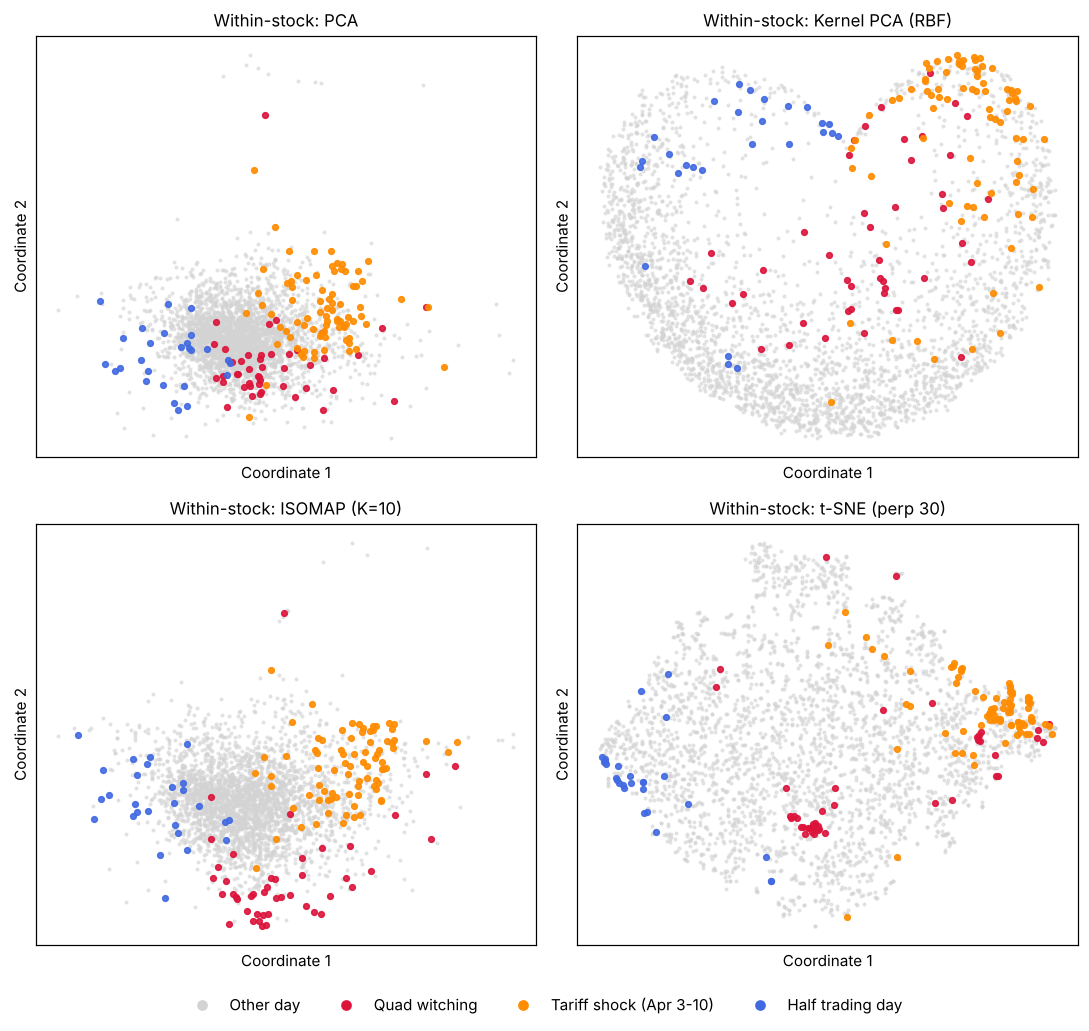

PCA                neighbor preservation = 0.112, same-stock neighbors = 0.032
Kernel PCA (RBF)   neighbor preservation = 0.076, same-stock neighbors = 0.027


ISOMAP (K=10)      neighbor preservation = 0.108, same-stock neighbors = 0.033
t-SNE (perp 30)    neighbor preservation = 0.422, same-stock neighbors = 0.068


In [26]:
emb_w = {
    "PCA": pca_w.transform(Zw)[:, :2],
    "Kernel PCA (RBF)": KernelPCA(n_components=2, kernel="rbf",
                                  gamma=1 / np.median(((Zw[:, None] - Zw[None]) ** 2).sum(-1))).fit_transform(Zw),
    "ISOMAP (K=10)": manifold.Isomap(n_neighbors=10, n_components=2).fit_transform(Zw),
    "t-SNE (perp 30)": manifold.TSNE(n_components=2, random_state=RANDOM_SEED).fit_transform(Zw),
}

fig, axes = plt.subplots(2, 2, figsize=[10, 9.4])
for ax, (name, Y) in zip(axes.flatten(), emb_w.items()):
    for t, col in DAY_COLORS.items():
        m = day_type == t
        ax.scatter(Y[m, 0], Y[m, 1], s=3 if t == "Other day" else 14, color=col,
                   alpha=0.5 if t == "Other day" else 0.9, label=t, zorder=1 if t == "Other day" else 3)
    ax.set_title(f"Within-stock: {name}", size=11)
    ax.set_xlabel("Coordinate 1", size=10); ax.set_ylabel("Coordinate 2", size=10)
    ax.set_xticks([]); ax.set_yticks([])
handles = [Line2D([0], [0], marker="o", ls="", color=c, label=t, markersize=6) for t, c in DAY_COLORS.items()]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.0))
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

for name, Y in emb_w.items():
    print(f"{name:18s} neighbor preservation = {neighbor_preservation(Zw, Y):.3f}, "
          f"same-stock neighbors = {same_stock_share(Y, labels):.3f}")

**Interpretation of the within-stock analysis.** Once stock identity is removed, the embeddings are organized by the **kind of trading day**. None of these labels were used in the fit.

* **Tariff-shock days (April 3–10)** lie at the high end of the activity direction in PCA and ISOMAP: every stock traded far more than usual. In t-SNE they form one compact group on the right.
* **Half trading days** sit at the opposite, low-activity end in every method, and form their own small group at the edge of the t-SNE map.
* **Quad-witching days** separate along a *different* direction. Averaged over stocks, on these days the number of trades is almost normal (+0.02 in $\log_{10}$). Market-hours dollar volume roughly doubles (+0.27), institutional \$50K dollar volume doubles (+0.31), and after-hours dollar volume rises about 5.5-fold (+0.74). This pattern is large index-rebalancing and expiry orders executed in the closing auction. So these days are not simply "busier" days: they are days with an unusual *composition* of trading. ISOMAP places them along its second axis, and t-SNE gathers many of them into a tight cluster.

Without the stock effect the methods rank as before on local neighborhoods (t-SNE 0.42, then PCA and ISOMAP about 0.11, then Kernel PCA 0.08). The overall levels are lower because day-to-day noise is less structured than the gaps between stocks.

Here the 2-D representations do recover economically meaningful information that is easy to miss in 15 separate time series. That makes them a plausible input to a later model, for example as daily "activity" and "composition" factors.

## 10. Conclusions {-}

1. **The 15 trading-activity variables are a good candidate for dimension reduction.** After a log transform they are tied together by the nesting of trade categories and by the identity
$$
\text{dollars} = \text{trades} \times \text{shares per trade} \times \text{price}.
$$
   Two principal components keep 91% of the variance: an overall **activity/size** factor and a **trade-size/price** factor.
2. **Linear structure dominates.** Because the relationships are close to linear in logs, PCA already captures the global structure. ISOMAP offers a modest improvement, and RBF Kernel PCA is worse, producing a horseshoe.
3. **Nonlinear methods help with local structure.** t-SNE keeps more than twice as many nearest neighbors as PCA. It recovers stock identity, and isolates NFLX's post-split days, with no supervision.
4. **Removing each stock's mean reveals the day-level structure.** A market-wide activity factor explains 68% of within-stock variance. The second direction separates quad-witching days (large institutional and closing-auction flow) from ordinary busy days such as the April tariff shock.

**Limits.** Each stock contributes only 60 random days, the embeddings depend on tuning parameters ($\gamma$, $K$, perplexity), and t-SNE coordinates cannot be interpreted or reused on new data the way PCA loadings can.